## Notebook 5: DINOv2


### 1. Imports and settings

In [1]:
import transformers
from transformers import AutoModel
import torch

m = AutoModel.from_pretrained("facebook/dinov3-vitb16-pretrain-lvd1689m")
print("loaded OK, hidden size:", m.config.hidden_size)
print("register tokens:", m.config.num_register_tokens)

x = torch.randn(1, 3, 336, 224)
with torch.no_grad():
    out = m(pixel_values=x).last_hidden_state
print("output shape:", tuple(out.shape))

W1110 15:38:49.464000 72680 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

loaded OK, hidden size: 768
register tokens: 4
output shape: (1, 299, 768)


In [ ]:
import hashlib
import json
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from PIL import Image

import torch
import torchvision
import transformers
from transformers import AutoModel

from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.feature_selection import f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

Image.MAX_IMAGE_PIXELS = None
warnings.filterwarnings("ignore")

# Paths
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".git").exists()), None)
assert ROOT is not None, "Open this notebook from inside the 281project repo"
PROC = ROOT / "data" / "processed"
FEATURE_DIR = ROOT / "data" / "features"
RESULTS_DIR = ROOT / "data" / "results"
FEATURE_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Network settings
HF_NAMES = {"dinov3_vits16": "facebook/dinov3-vits16-pretrain-lvd1689m",
            "dinov3_vitb16": "facebook/dinov3-vitb16-pretrain-lvd1689m",
            "dinov3_vitl16": "facebook/dinov3-vitl16-pretrain-lvd1689m"}
MODEL_DIMS = {"dinov3_vits16": 384, "dinov3_vitb16": 768, "dinov3_vitl16": 1024}
MODEL_NAME = "dinov3_vitb16"
HF_NAME = HF_NAMES[MODEL_NAME]
PATCH = 16                            # DINOv3 patch size (DINOv2 used 14)
EMBED_WIDTH = 224                     # try 336 or 448 for finer detail (slower)
POOLING = "cls+mean"                  # "cls" or "cls+mean"
BATCH_SIZE = 32
RECOMPUTE_EMBEDDINGS = False
IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
IMAGENET_STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)

# Keep same model settings
EMBED_DIM = MODEL_DIMS[MODEL_NAME] * (2 if POOLING == "cls+mean" else 1)
PCA_DIMS = [16, 32, 64, 128, 256, 512, EMBED_DIM]
C_GRID = np.logspace(-6, 2, 13)
CLASS_WEIGHTS = [None, "balanced"]
MAX_ITER = 3000
SELECTION_RULE = "one_se"
N_VAL_BOOTSTRAP = 200

# refit for cached embedings
RESNET_PCA, RESNET_C, RESNET_WEIGHT = 64, 1e-4, None
DINOV2_PCA, DINOV2_C, DINOV2_WEIGHT = 32, float(np.logspace(-6, 2, 13)[2]), None   # C = 2.15e-5
DINOV2_MS_PER_IMAGE = 203.3           # measured in 5-dinov2 on this Mac (CPU, 1 thread)

# Baseline, test, timing, settings
N_GUESS_SEEDS = 1000
N_BOOTSTRAP = 1000
N_TIMING_IMAGES = 50
TIMING_CPU_THREADS = 1
N_GALLERY = 5
OFFSET_GRID = np.round(np.arange(-3, 1.0001, 0.1), 2)
SEED = 281
CLASS_NAMES = ["Small", "Medium", "Large"]
CLASS_COLORS = ["tab:green", "tab:orange", "tab:blue"]

if torch.cuda.is_available():
    DEVICE = "cuda"
elif torch.backends.mps.is_available():
    DEVICE = "mps"
else:
    DEVICE = "cpu"
torch.manual_seed(SEED)
print("PyTorch", torch.__version__, "| transformers", transformers.__version__, "| device:", DEVICE)

PyTorch 2.15.0 | transformers 5.22.2 | device: mps


### 2. Load Data

In [3]:
manifest = pd.read_csv(PROC / "manifest.csv", keep_default_na=False)
splits, y = {}, {}
for split_name in ["train", "val", "test"]:
    splits[split_name] = manifest[manifest["split"] == split_name].reset_index(drop=True)
    y[split_name] = splits[split_name]["label"].to_numpy()
    c = np.bincount(y[split_name], minlength=3)
    print(split_name, "-> Small:", c[0], " Medium:", c[1], " Large:", c[2], " total:", c.sum())

for column in ["source_id", "group_id"]:
    ids = {s: set(splits[s][column]) for s in splits}
    overlap = len(ids["train"] & ids["val"]) + len(ids["train"] & ids["test"]) + len(ids["val"] & ids["test"])
    print(column, "shared between splits:", overlap)
    assert overlap == 0, "Leakage between splits - re-run 1-preprocessing.ipynb"

is_original = (splits["train"]["variant"] == "original").to_numpy()
y_train_maps = y["train"][is_original]

# Split fingerprint: the same function as 1-preprocessing. Same 10 characters = same split as your teammates'.
def split_fingerprint(frame):
    cols = ["image_id", "split", "variant", "label", "source_id"]
    rows = frame.loc[frame["variant"].isin(["original", "rescan"]), cols].astype(str)
    rows = rows.sort_values("image_id").reset_index(drop=True)
    return hashlib.sha1(rows.to_csv(index=False, lineterminator="\n").encode()).hexdigest()[:10]


PREPROCESS = json.loads((PROC / "preprocess_config.json").read_text())
SPLIT_FINGERPRINT = split_fingerprint(manifest)
assert SPLIT_FINGERPRINT == PREPROCESS.get("split_fingerprint", SPLIT_FINGERPRINT), \
    "manifest.csv doesn't match the last 1-preprocessing run - re-run 1-preprocessing and 2-augment"
print("Split fingerprint:", SPLIT_FINGERPRINT)

# Saved embeddings are reused only if this matches. It changes when the split's rows change, when
# 1-preprocessing is re-run, or (train only) when 2-augment is re-run, since any of those can change the pixels.
AUGMENT = json.loads((PROC / "augment_config.json").read_text()) if (PROC / "augment_config.json").exists() else {}


def data_version(split_name):
    rows = splits[split_name][["path", "aug_params"]].to_csv(index=False, lineterminator="\n")
    stamp = PREPROCESS.get("created", "") + (AUGMENT.get("created", "") if split_name == "train" else "")
    return hashlib.sha1((rows + stamp).encode()).hexdigest()[:16]

train -> Small: 590  Medium: 1240  Large: 1240  total: 3070
val -> Small: 26  Medium: 54  Large: 213  total: 293
test -> Small: 25  Medium: 53  Large: 213  total: 291
source_id shared between splits: 0
group_id shared between splits: 0


### 3. (recap) Baselines

In [4]:
def macro_mae(y_true, y_pred):
    y_true = np.asarray(y_true)
    steps = np.abs(np.asarray(y_pred) - y_true)
    return float(np.mean([steps[y_true == c].mean() for c in [0, 1, 2] if np.any(y_true == c)]))

def steps_off_per_class(y_true, y_pred):
    return np.array([np.abs(y_pred[y_true == c] - c).mean() for c in [0, 1, 2]])

def get_scores(y_true, y_pred):
    return {"accuracy": accuracy_score(y_true, y_pred),
            "balanced_acc": balanced_accuracy_score(y_true, y_pred),
            "macro_f1": f1_score(y_true, y_pred, labels=[0, 1, 2], average="macro", zero_division=0),
            "macro_mae": macro_mae(y_true, y_pred)}

def macro_f1_fast(y_true, y_pred):
    counts = np.bincount(3 * y_true + y_pred, minlength=9).reshape(3, 3)
    tp = np.diag(counts)
    fp, fn = counts.sum(axis=0) - tp, counts.sum(axis=1) - tp
    den = 2 * tp + fp + fn
    return np.divide(2 * tp, den, out=np.zeros(3), where=den > 0).mean()

no_features_train = np.zeros((len(y_train_maps), 1))
majority = DummyClassifier(strategy="most_frequent").fit(no_features_train, y_train_maps)

baseline_rows, majority_pred = [], {}
guess_f1, guess_per_class, guess_steps = {}, {}, {}
for split_name in ["val", "test"]:
    nf = np.zeros((len(y[split_name]), 1))
    majority_pred[split_name] = majority.predict(nf)
    baseline_rows.append({"model": "majority_class", "split": split_name,
                          **get_scores(y[split_name], majority_pred[split_name])})
    runs, per_class, steps = [], [], []
    for seed in range(N_GUESS_SEEDS):
        guess = DummyClassifier(strategy="stratified", random_state=seed).fit(no_features_train, y_train_maps).predict(nf)
        runs.append(get_scores(y[split_name], guess))
        per_class.append(f1_score(y[split_name], guess, labels=[0, 1, 2], average=None, zero_division=0))
        steps.append(steps_off_per_class(y[split_name], guess))
    runs = pd.DataFrame(runs)
    guess_f1[split_name] = runs["macro_f1"].to_numpy()
    guess_per_class[split_name] = np.mean(per_class, axis=0)
    guess_steps[split_name] = np.mean(steps, axis=0)
    baseline_rows.append({"model": "random_guess (mean)", "split": split_name, **runs.mean().to_dict(),
                          "macro_f1_low": np.percentile(guess_f1[split_name], 2.5),
                          "macro_f1_high": np.percentile(guess_f1[split_name], 97.5)})
baseline_table = pd.DataFrame(baseline_rows)

def baseline_value(model, split_name, column="macro_f1"):
    m = baseline_table[(baseline_table["model"] == model) & (baseline_table["split"] == split_name)]
    return m[column].item()

majority_val_f1, majority_test_f1 = baseline_value("majority_class", "val"), baseline_value("majority_class", "test")
chance_val_f1, chance_test_f1 = baseline_value("random_guess (mean)", "val"), baseline_value("random_guess (mean)", "test")
chance_test_range = (baseline_value("random_guess (mean)", "test", "macro_f1_low"),
                     baseline_value("random_guess (mean)", "test", "macro_f1_high"))
majority_test_mae = baseline_value("majority_class", "test", "macro_mae")
chance_test_mae = baseline_value("random_guess (mean)", "test", "macro_mae")
baseline_table.round(3)

,model,split,accuracy,balanced_acc,macro_f1,macro_mae,macro_f1_low,macro_f1_high
0,majority_class,val,0.727,0.333,0.281,1.00,NaN,NaN
1,random_guess (mean),val,0.571,0.333,0.332,0.94,0.277,0.391
2,majority_class,test,0.732,0.333,0.282,1.00,NaN,NaN
3,random_guess (mean),test,0.574,0.333,0.332,0.94,0.279,0.389


### 4. Dinov3 requirements
patch size is 16, rather than the 14 in dinov2

### 5. DINOv3 processing

In [5]:
with Image.open(PROC / splits["train"]["path"][0]) as img:
    processed_width, processed_height = img.size

def snap(v):
    return max(1, round(v / PATCH)) * PATCH

EMBED_SIZE = (snap(EMBED_WIDTH), snap(EMBED_WIDTH * processed_height / processed_width))   # (width, height)
GRID = (EMBED_SIZE[1] // PATCH, EMBED_SIZE[0] // PATCH)                                     # (rows, cols)
print(f"Processed maps: {processed_width} x {processed_height} -> network input {EMBED_SIZE[0]} x {EMBED_SIZE[1]} "
      f"= {GRID[0]} x {GRID[1]} = {GRID[0] * GRID[1]} patches")

def prepare_image(path):
    with Image.open(path) as img:
        small = img.convert("RGB").resize(EMBED_SIZE, Image.BICUBIC)
    pixels = (np.asarray(small, dtype=np.float32) / 255.0 - IMAGENET_MEAN) / IMAGENET_STD
    return torch.from_numpy(np.ascontiguousarray(pixels.transpose(2, 0, 1)))

def to_displayable(t):
    return np.clip(t.numpy().transpose(1, 2, 0) * IMAGENET_STD + IMAGENET_MEAN, 0, 1)

Processed maps: 673 x 1024 -> network input 224 x 336 = 21 x 14 = 294 patches


### 6. DINOv2 steps


In [6]:
extractor = AutoModel.from_pretrained(HF_NAME)
extractor.eval()
for p in extractor.parameters():
    p.requires_grad = False
extractor = extractor.to(DEVICE)
N_REG = extractor.config.num_register_tokens
assert extractor.config.hidden_size == MODEL_DIMS[MODEL_NAME]
print(f"{MODEL_NAME}: {sum(p.numel() for p in extractor.parameters()) / 1e6:.1f} million weights, "
      f"all frozen, {N_REG} register tokens")

def embed_batch(batch):
    """(B, 3, H, W) -> (B, EMBED_DIM): CLS token, optionally followed by the mean of the patch tokens."""
    h = extractor(pixel_values=batch).last_hidden_state      # (B, 1 + N_REG + patches, hidden)
    cls = h[:, 0]
    if POOLING == "cls":
        return cls
    return torch.cat([cls, h[:, 1 + N_REG:].mean(dim=1)], dim=1)

# One random train map per class (reused below)
rng = np.random.default_rng(SEED)
example_rows = {c: rng.choice(np.where(is_original & (y["train"] == c))[0]) for c in range(3)}

x = prepare_image(PROC / splits["train"].loc[example_rows[0], "path"]).unsqueeze(0).to(DEVICE)
with torch.no_grad():
    h = extractor(pixel_values=x).last_hidden_state
    emb = embed_batch(x)
assert h.shape[1] == 1 + N_REG + GRID[0] * GRID[1], f"unexpected token count {h.shape[1]}"
assert emb.shape == (1, EMBED_DIM), emb.shape
print(pd.DataFrame([
    {"output": "input image", "shape": tuple(x.shape)},
    {"output": "all tokens (CLS + registers + patches)", "shape": tuple(h.shape)},
    {"output": f"embedding ({POOLING})", "shape": tuple(emb.shape)},
]).to_string(index=False))

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

dinov3_vitb16: 85.7 million weights, all frozen, 4 register tokens
                                output            shape
                           input image (1, 3, 336, 224)
all tokens (CLS + registers + patches)    (1, 299, 768)
                  embedding (cls+mean)        (1, 1536)


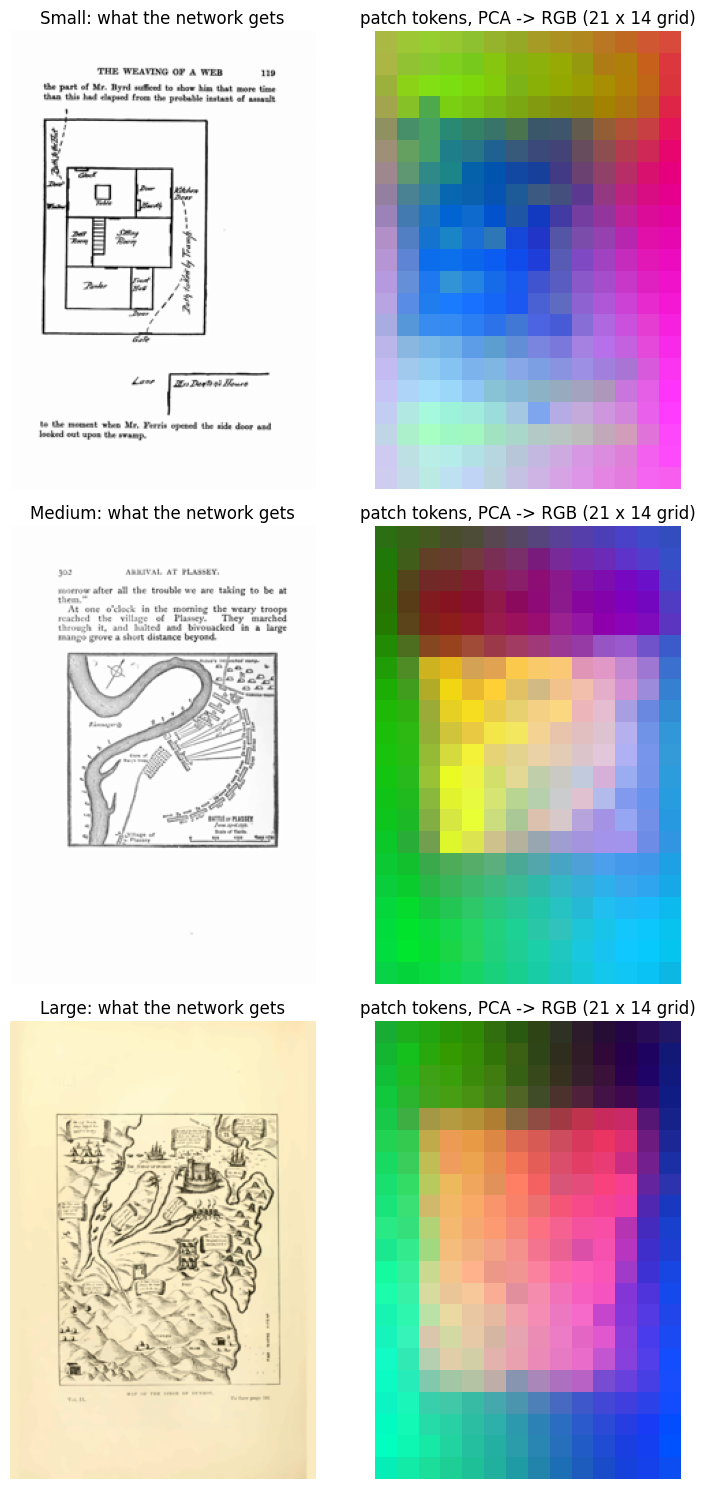

In [7]:
fig, axes = plt.subplots(3, 2, figsize=(8, 15))
for c in range(3):
    t = prepare_image(PROC / splits["train"].loc[example_rows[c], "path"])
    with torch.no_grad():
        tokens = extractor(pixel_values=t.unsqueeze(0).to(DEVICE)).last_hidden_state[0, 1 + N_REG:].cpu().numpy()
    rgb = PCA(n_components=3, random_state=SEED).fit_transform(tokens)
    rgb = (rgb - rgb.min(0)) / (rgb.max(0) - rgb.min(0) + 1e-9)
    axes[c, 0].imshow(to_displayable(t)); axes[c, 0].set_title(f"{CLASS_NAMES[c]}: what the network gets")
    axes[c, 1].imshow(rgb.reshape(GRID[0], GRID[1], 3), interpolation="nearest")
    axes[c, 1].set_title(f"patch tokens, PCA -> RGB ({GRID[0]} x {GRID[1]} grid)")
    for ax in axes[c]:
        ax.axis("off")
plt.tight_layout(); plt.show()

### 7. run embeddings for each image
takes a few minutes! 
checks manifest rows

In [8]:
CACHE_INFO = {"model": HF_NAME, "embed_size": list(EMBED_SIZE), "pooling": POOLING, "resize": "bicubic"}

def embed_paths(paths, desc):
    chunks, t0 = [], time.perf_counter()
    for start in range(0, len(paths), BATCH_SIZE):
        batch = torch.stack([prepare_image(PROC / p) for p in paths[start:start + BATCH_SIZE]]).to(DEVICE)
        with torch.no_grad():
            chunks.append(embed_batch(batch).cpu().numpy())
        print(f"\r{desc}: {min(start + BATCH_SIZE, len(paths))}/{len(paths)} images ({time.perf_counter() - t0:.0f} s)", end="")
    print()
    return np.concatenate(chunks).astype(np.float32), time.perf_counter() - t0

def cache_file(split_name):
    return FEATURE_DIR / f"{MODEL_NAME}_{split_name}.npz"

def load_saved(split_name, paths):
    f = cache_file(split_name)
    if RECOMPUTE_EMBEDDINGS or not f.exists():
        return None
    saved = np.load(f, allow_pickle=False)
    same_data = "data_version" in saved.files and str(saved["data_version"]) == data_version(split_name)
    if saved["paths"].tolist() == list(paths) and json.loads(str(saved["info"])) == CACHE_INFO and same_data:
        return saved["X"], float(saved["seconds"]), str(saved["device"])
    print(f"{f.name} is out of date - recomputing")
    return None

X, extract_seconds, extract_device = {}, {}, {}
for split_name in ["train", "val", "test"]:
    paths = splits[split_name]["path"].tolist()
    saved = load_saved(split_name, paths)
    if saved is not None:
        X[split_name], extract_seconds[split_name], extract_device[split_name] = saved
        print(f"{split_name}: loaded {len(paths)} saved embeddings")
    else:
        X[split_name], extract_seconds[split_name] = embed_paths(paths, split_name)
        extract_device[split_name] = DEVICE
        np.savez(cache_file(split_name), X=X[split_name], paths=np.array(paths), info=json.dumps(CACHE_INFO),
                 data_version=data_version(split_name),
                 seconds=extract_seconds[split_name], device=DEVICE)
    print(f"   {split_name}: {X[split_name].shape}")
assert X["train"].shape[1] == EMBED_DIM

train: 3070/3070 images (236 s)
   train: (3070, 1536)
val: 293/293 images (23 s)
   val: (293, 1536)
test: 291/291 images (21 s)
   test: (291, 1536)


##### load resnet for comparison

In [9]:
def load_cached(prefix, dim_name):
    out = {}
    for s in splits:
        f = FEATURE_DIR / f"{prefix}_{s}.npz"
        if not f.exists():
            print(f"{f.name} not found - run {dim_name}; that comparison will be skipped")
            return None
        saved = np.load(f, allow_pickle=False)
        if (saved["paths"].tolist() != splits[s]["path"].tolist() or "data_version" not in saved.files
                or str(saved["data_version"]) != data_version(s)):
            print(f"{f.name} doesn't match the current manifest or images - re-run {dim_name}")
            return None
        out[s] = saved["X"]
    return out

X_res = load_cached("resnet50", "4-pretrained_feature.ipynb")
X_d2 = load_cached("dinov2_vitb14", "5-DINOv2.ipynb")

In [10]:
def load_resnet_embeddings():
    out = {}
    for s in splits:
        f = FEATURE_DIR / f"resnet50_{s}.npz"
        if not f.exists():
            print(f"{f.name} not found - run 4-pretrained_feature.ipynb; ResNet comparisons will be skipped")
            return None
        saved = np.load(f, allow_pickle=False)
        if (saved["paths"].tolist() != splits[s]["path"].tolist() or "data_version" not in saved.files
                or str(saved["data_version"]) != data_version(s)):
            print(f"{f.name} doesn't match the current manifest or images - re-run 4-pretrained_feature.ipynb")
            return None
        out[s] = saved["X"]
    return out

def chosen_setting(results_file, default):
    """(PCA size, C, class weight) that another notebook chose on this same split, or `default` if its results
    are missing or come from a different split."""
    f = RESULTS_DIR / results_file
    if f.exists():
        r = json.loads(f.read_text())
        if r.get("split_fingerprint") == SPLIT_FINGERPRINT:
            setting = (int(r["pca_dims"]), float(r["C"]), "balanced" if r["class_weight"] == "balanced" else None)
            print(f"{results_file}: PCA {setting[0]}, C = {setting[1]:.2e}, class weight {setting[2]}")
            return setting
    print(f"{results_file} is missing or from another split - using the hard-coded setting {default}. "
          f"Re-run that notebook first to use what it chose on this split.")
    return default


X_res = load_resnet_embeddings()
RESNET_PCA, RESNET_C, RESNET_WEIGHT = chosen_setting("4-pretrained_feature.json", (RESNET_PCA, RESNET_C, RESNET_WEIGHT))
DINOV2_PCA, DINOV2_C, DINOV2_WEIGHT = chosen_setting("5-dinov2.json", (DINOV2_PCA, DINOV2_C, DINOV2_WEIGHT))

#### timing

In [11]:
timing_paths = splits["train"]["path"].tolist()[:N_TIMING_IMAGES]
threads_before = torch.get_num_threads()
extractor.to("cpu"); torch.set_num_threads(TIMING_CPU_THREADS)
try:
    prep_s = net_s = 0.0
    with torch.no_grad():
        embed_batch(prepare_image(PROC / timing_paths[0]).unsqueeze(0))   # warm-up
        for p in timing_paths:
            t = time.perf_counter(); one = prepare_image(PROC / p).unsqueeze(0); prep_s += time.perf_counter() - t
            t = time.perf_counter(); embed_batch(one); net_s += time.perf_counter() - t
finally:
    torch.set_num_threads(threads_before); extractor.to(DEVICE)
prep_ms, network_ms = 1000 * prep_s / len(timing_paths), 1000 * net_s / len(timing_paths)
embed_ms_per_image = prep_ms + network_ms
print(f"CPU, 1 thread: {embed_ms_per_image:.1f} ms per image (load+prepare {prep_ms:.1f}, network {network_ms:.1f})")

CPU, 1 thread: 156.0 ms per image (load+prepare 14.2, network 141.9)


### 8. Check Embeddings

##### 8a. Which embedding numbers differ most between classes?

DINOv3: 1080 of 1536 numbers (70.3%) differ at p < 0.001; 887 pass Bonferroni; top F = 136
DINOv2: 984 of 1536 numbers (64.1%) differ at p < 0.001; 799 pass Bonferroni; top F = 75
ResNet-50: 280 of 2048 numbers (13.7%) differ at p < 0.001; 146 pass Bonferroni; top F = 60


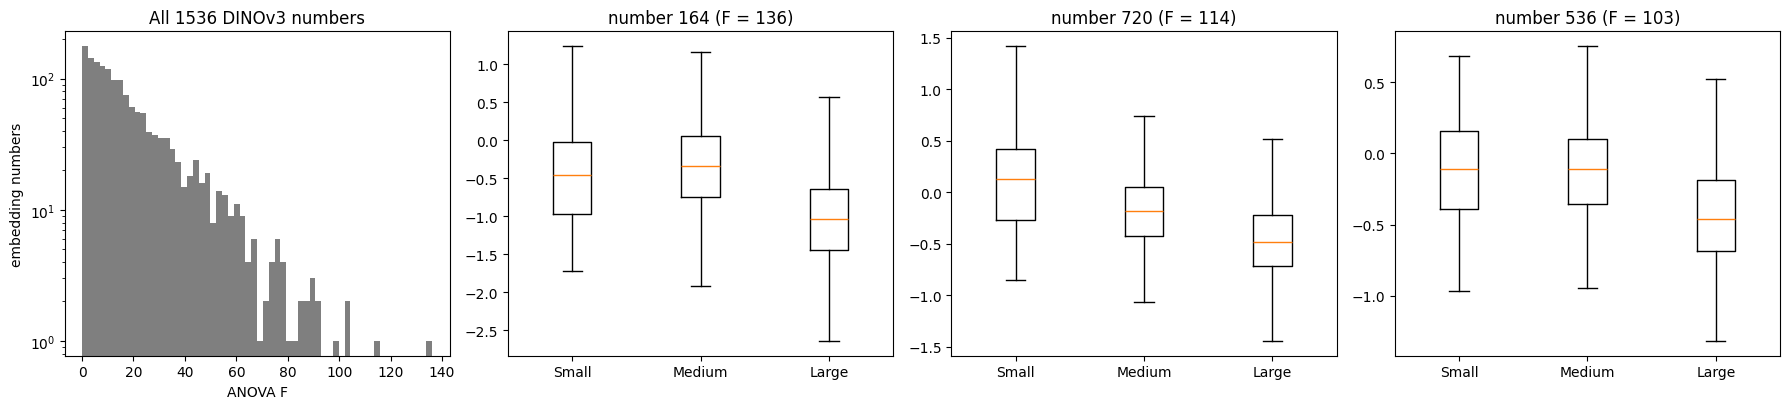

In [12]:
def anova_summary(Xm, name):
    F_, p_ = f_classif(Xm, y_train_maps)
    F_ = np.nan_to_num(F_)
    n = Xm.shape[1]
    print(f"{name}: {(p_ < 0.001).sum()} of {n} numbers ({(p_ < 0.001).mean():.1%}) differ at p < 0.001; "
          f"{(p_ < 0.05 / n).sum()} pass Bonferroni; top F = {F_.max():.0f}")
    return F_

X_train_maps = X["train"][is_original]
F = anova_summary(X_train_maps, "DINOv3")
if X_d2 is not None: anova_summary(X_d2["train"][is_original], "DINOv2")
if X_res is not None: anova_summary(X_res["train"][is_original], "ResNet-50")

top_dims = np.argsort(F)[::-1][:3]
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
axes[0].hist(F, bins=60, color="tab:gray"); axes[0].set_yscale("log")
axes[0].set_xlabel("ANOVA F"); axes[0].set_ylabel("embedding numbers"); axes[0].set_title(f"All {EMBED_DIM} DINOv3 numbers")
for ax, dim in zip(axes[1:], top_dims):
    ax.boxplot([X_train_maps[y_train_maps == c, dim] for c in range(3)], showfliers=False)
    ax.set_xticks([1, 2, 3], CLASS_NAMES); ax.set_title(f"number {dim} (F = {F[dim]:.0f})")
plt.tight_layout(); plt.show()

##### 8b. PCA of resnet and dinos

ResNet-50: 50% of variance in 61 components, 80% in 271, first two = 10.7%
DINOv2: 50% of variance in 11 components, 80% in 76, first two = 22.1%
DINOv3: 50% of variance in 15 components, 80% in 93, first two = 17.3%


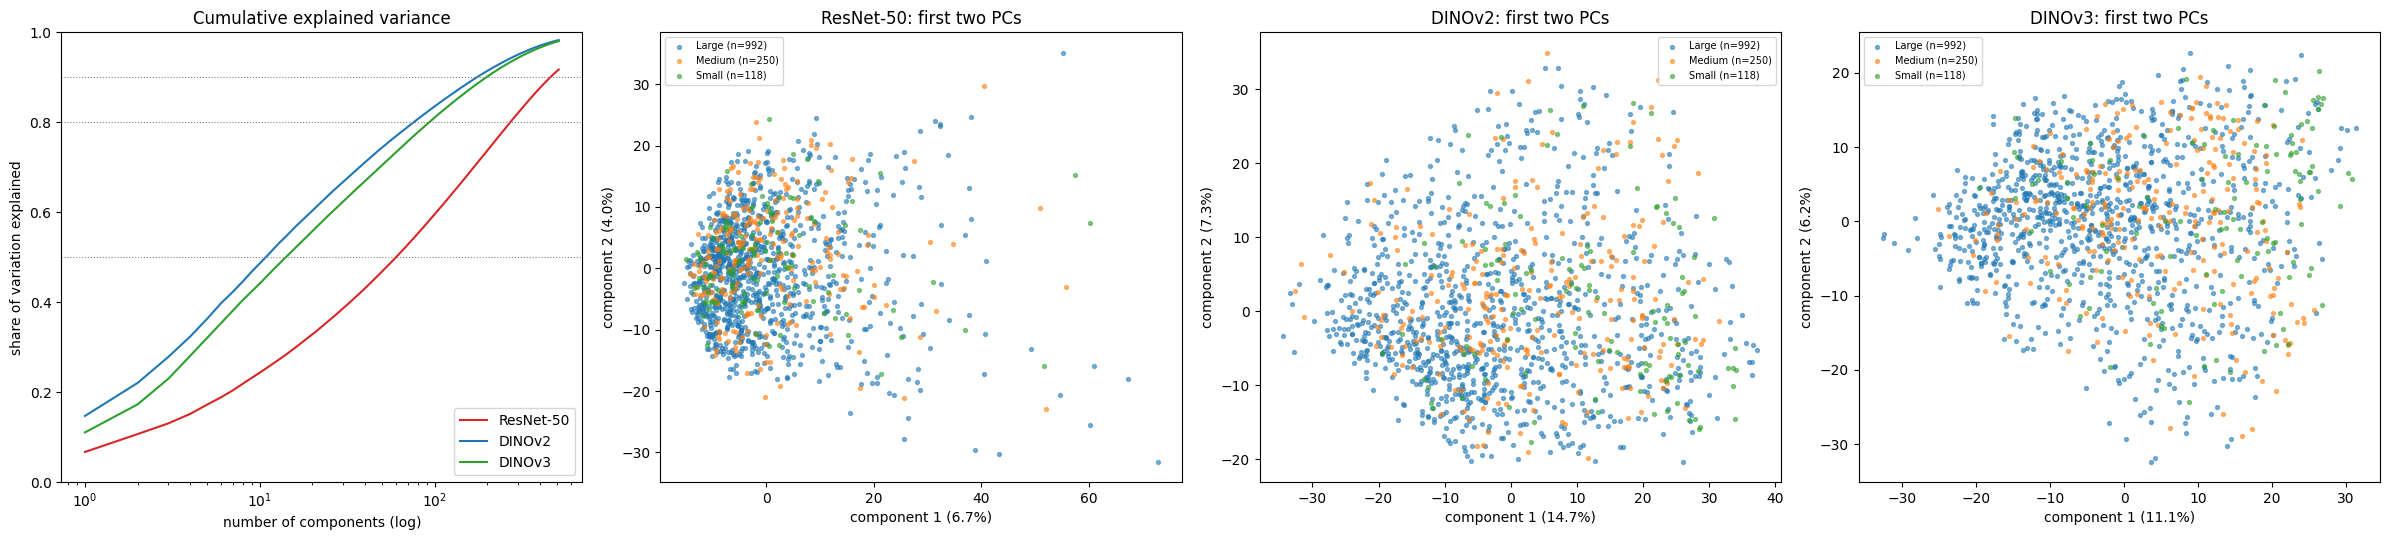

In [13]:
models_emb = {"DINOv3": X}
if X_d2 is not None: models_emb = {"DINOv2": X_d2, **models_emb}
if X_res is not None: models_emb = {"ResNet-50": X_res, **models_emb}
line_colors = {"ResNet-50": "tab:red", "DINOv2": "tab:blue", "DINOv3": "tab:green"}

viz = {}
for name, Xm in models_emb.items():
    sc = StandardScaler().fit(Xm["train"][is_original])
    pca = PCA(n_components=min(512, is_original.sum() - 1), random_state=SEED).fit(sc.transform(Xm["train"][is_original]))
    viz[name] = {"pca": pca, "Z": pca.transform(sc.transform(Xm["train"][is_original]))}

fig, axes = plt.subplots(1, 1 + len(viz), figsize=(6 * (1 + len(viz)), 5.5))
for name, v in viz.items():
    cum = np.cumsum(v["pca"].explained_variance_ratio_)
    axes[0].plot(np.arange(1, len(cum) + 1), cum, color=line_colors[name], label=name)
    print(f"{name}: 50% of variance in {np.searchsorted(cum, 0.5) + 1} components, "
          f"80% in {np.searchsorted(cum, 0.8) + 1}, first two = {cum[1]:.1%}")
for level in [0.5, 0.8, 0.9]:
    axes[0].axhline(level, color="gray", linestyle=":", linewidth=0.8)
axes[0].set_xscale("log"); axes[0].set_ylim(0, 1)
axes[0].set_xlabel("number of components (log)"); axes[0].set_ylabel("share of variation explained")
axes[0].set_title("Cumulative explained variance"); axes[0].legend()
for ax, (name, v) in zip(axes[1:], viz.items()):
    for c in [2, 1, 0]:
        rows = y_train_maps == c
        ax.scatter(v["Z"][rows, 0], v["Z"][rows, 1], s=8, alpha=0.55, color=CLASS_COLORS[c], label=f"{CLASS_NAMES[c]} (n={rows.sum()})")
    ax.set_xlabel(f"component 1 ({v['pca'].explained_variance_ratio_[0]:.1%})")
    ax.set_ylabel(f"component 2 ({v['pca'].explained_variance_ratio_[1]:.1%})")
    ax.set_title(f"{name}: first two PCs"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

##### 8c. tSNE and neighbor check


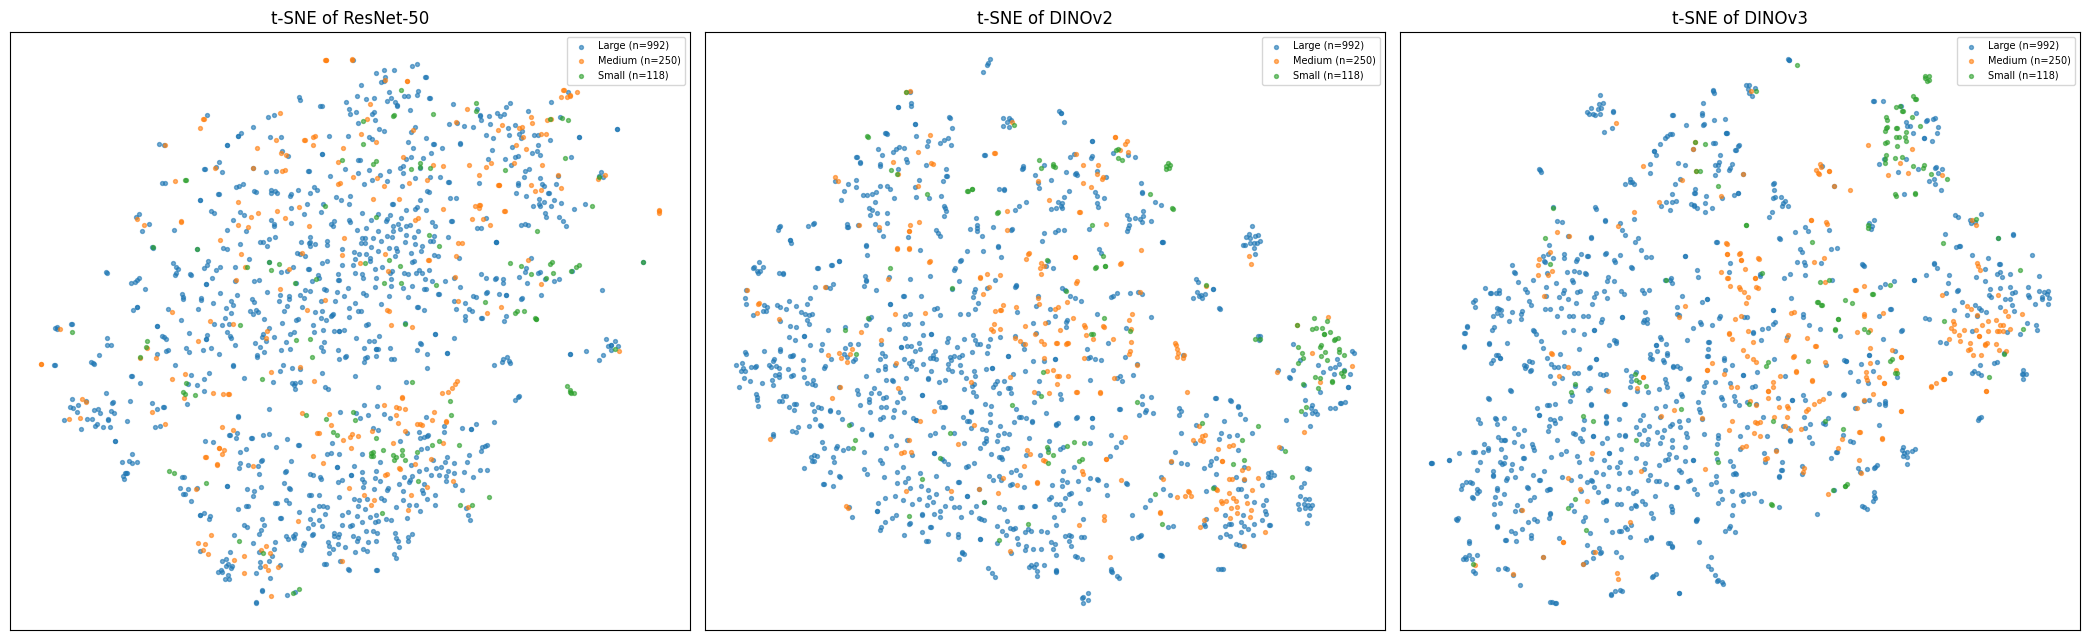

,ResNet-50: same-class share of 10 nearest,DINOv2: same-class share of 10 nearest,DINOv3: same-class share of 10 nearest,if neighbors were random
Small,0.250,0.344,0.344,0.087
Medium,0.329,0.390,0.452,0.184
Large,0.790,0.800,0.794,0.729


In [14]:
nn_rows = {}
fig, axes = plt.subplots(1, len(viz), figsize=(7 * len(viz), 6.5))
axes = np.atleast_1d(axes)
for ax, (name, v) in zip(axes, viz.items()):
    Z50 = v["Z"][:, :50]
    T2 = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto", random_state=SEED).fit_transform(Z50)
    for c in [2, 1, 0]:
        rows = y_train_maps == c
        ax.scatter(T2[rows, 0], T2[rows, 1], s=8, alpha=0.6, color=CLASS_COLORS[c], label=f"{CLASS_NAMES[c]} (n={rows.sum()})")
    ax.set_xticks([]); ax.set_yticks([]); ax.set_title(f"t-SNE of {name}"); ax.legend(fontsize=7)
    nbrs = NearestNeighbors(n_neighbors=11).fit(Z50).kneighbors(Z50, return_distance=False)[:, 1:]
    same = (y_train_maps[nbrs] == y_train_maps[:, None]).mean(axis=1)
    nn_rows[f"{name}: same-class share of 10 nearest"] = [same[y_train_maps == c].mean() for c in range(3)]
nn_rows["if neighbors were random"] = [np.mean(y_train_maps == c) for c in range(3)]
plt.tight_layout(); plt.show()
display(pd.DataFrame(nn_rows, index=CLASS_NAMES).round(3))

##### 8d. tune validation set

In [15]:
n_val = len(y["val"])
val_resamples = np.random.default_rng(SEED).integers(0, n_val, size=(N_VAL_BOOTSTRAP, n_val))

search_rows, t_start = [], time.perf_counter()
scaler = StandardScaler().fit(X["train"])
train_scaled, val_scaled = scaler.transform(X["train"]), scaler.transform(X["val"])

for n_dims in PCA_DIMS:
    t = time.perf_counter()
    if n_dims < EMBED_DIM:
        pca = PCA(n_components=n_dims, random_state=SEED).fit(train_scaled)
        train_in, val_in = pca.transform(train_scaled), pca.transform(val_scaled)
    else:
        train_in, val_in = train_scaled, val_scaled
    pca_seconds = time.perf_counter() - t
    for class_weight in CLASS_WEIGHTS:
        weighting = "balanced" if class_weight == "balanced" else "none"
        for C in C_GRID:
            logreg = LogisticRegression(C=C, class_weight=class_weight, max_iter=MAX_ITER, random_state=SEED)
            t = time.perf_counter()
            logreg.fit(train_in, y["train"])
            fit_s = time.perf_counter() - t + pca_seconds
            val_pred = logreg.predict(val_in)
            search_rows.append({
                "pca_dims": n_dims, "weighting": weighting, "C": C,
                "train_macro_f1": macro_f1_fast(y["train"], logreg.predict(train_in)),
                "val_macro_f1": macro_f1_fast(y["val"], val_pred),
                "val_f1_se": np.std([macro_f1_fast(y["val"][r], val_pred[r]) for r in val_resamples]),
                "converged": bool(np.max(logreg.n_iter_) < MAX_ITER), "fit_seconds": fit_s})
        best_here = max(r["val_macro_f1"] for r in search_rows if r["pca_dims"] == n_dims and r["weighting"] == weighting)
        print(f"PCA {n_dims:>4} | {weighting:<8} | best val macro-F1 = {best_here:.3f}  ({time.perf_counter() - t_start:.0f} s)")
search = pd.DataFrame(search_rows)
print(f"\n{(~search['converged']).sum()} of {len(search)} fits stopped at MAX_ITER before converging")

PCA   16 | none     | best val macro-F1 = 0.602  (0 s)
PCA   16 | balanced | best val macro-F1 = 0.525  (0 s)
PCA   32 | none     | best val macro-F1 = 0.582  (1 s)
PCA   32 | balanced | best val macro-F1 = 0.542  (1 s)
PCA   64 | none     | best val macro-F1 = 0.602  (1 s)
PCA   64 | balanced | best val macro-F1 = 0.561  (1 s)
PCA  128 | none     | best val macro-F1 = 0.611  (2 s)
PCA  128 | balanced | best val macro-F1 = 0.593  (2 s)
PCA  256 | none     | best val macro-F1 = 0.609  (3 s)
PCA  256 | balanced | best val macro-F1 = 0.594  (3 s)
PCA  512 | none     | best val macro-F1 = 0.607  (5 s)
PCA  512 | balanced | best val macro-F1 = 0.592  (7 s)
PCA 1536 | none     | best val macro-F1 = 0.616  (9 s)
PCA 1536 | balanced | best val macro-F1 = 0.596  (12 s)

0 of 182 fits stopped at MAX_ITER before converging


In [17]:
best = search.loc[search["val_macro_f1"].idxmax()]
threshold = best["val_macro_f1"] - best["val_f1_se"]
tied = search[search["val_macro_f1"] >= threshold]
simplest = tied.sort_values(["pca_dims", "C", "val_macro_f1"], ascending=[True, True, False]).iloc[0]
chosen = simplest if SELECTION_RULE == "one_se" else best

def pca_label(n):
    return "no PCA" if n >= EMBED_DIM else f"PCA {int(n)}"

def describe(r):
    return (f"{pca_label(r['pca_dims'])}, weighting {r['weighting']}, C = {r['C']:.1e}: val macro-F1 "
            f"{r['val_macro_f1']:.3f} (SE {r['val_f1_se']:.3f}), train {r['train_macro_f1']:.3f}")

print("Highest val score:", describe(best))
print(f"Within one SE (>= {threshold:.3f}): {len(tied)} of {len(search)} settings")
print("Simplest of those:", describe(simplest))
print(f"\nChosen ({SELECTION_RULE}):", describe(chosen))
print(f"Random guessing on val: {chance_val_f1:.3f}   Majority class on val: {majority_val_f1:.3f}")
(search.sort_values("val_macro_f1", ascending=False).head(10)
       .assign(C=lambda d: d["C"].map("{:.1e}".format)).round(3).reset_index(drop=True))

Highest val score: no PCA, weighting none, C = 4.6e-04: val macro-F1 0.616 (SE 0.040), train 0.806
Within one SE (>= 0.576): 33 of 182 settings
Simplest of those: PCA 16, weighting none, C = 2.2e-05: val macro-F1 0.602 (SE 0.036), train 0.631

Chosen (one_se): PCA 16, weighting none, C = 2.2e-05: val macro-F1 0.602 (SE 0.036), train 0.631
Random guessing on val: 0.332   Majority class on val: 0.281


,pca_dims,weighting,C,train_macro_f1,val_macro_f1,val_f1_se,converged,fit_seconds
0,1536,none,4.6e-04,0.806,0.616,0.040,True,0.130
1,128,none,2.2e-03,0.787,0.611,0.039,True,0.109
2,256,none,4.6e-04,0.792,0.609,0.040,True,0.138
3,512,none,4.6e-04,0.803,0.607,0.040,True,0.272
4,128,none,4.6e-04,0.760,0.606,0.037,True,0.107
5,128,none,2.2e-05,0.648,0.603,0.036,True,0.099
6,16,none,2.2e-05,0.631,0.602,0.036,True,0.038
7,64,none,4.6e-04,0.727,0.602,0.036,True,0.069
8,1536,none,1.0e-04,0.726,0.602,0.036,True,0.077
9,512,none,1.0e-04,0.725,0.602,0.036,True,0.271


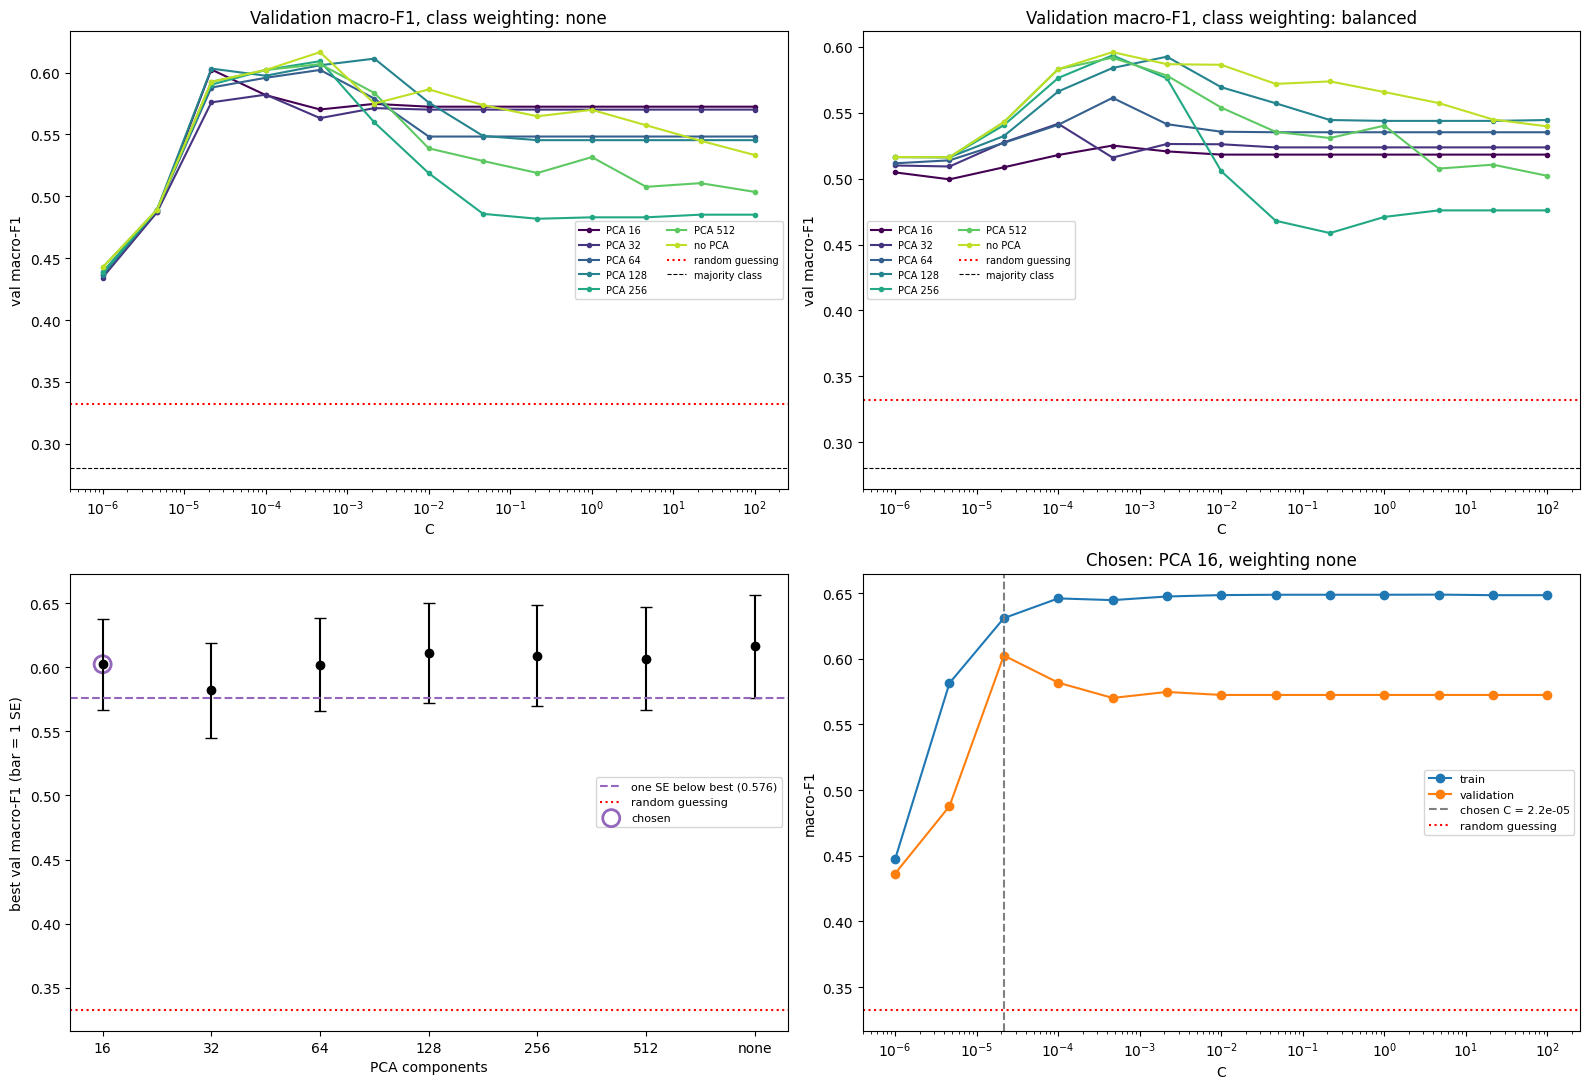

In [18]:
fig = plt.figure(figsize=(16, 11))
size_colors = plt.cm.viridis(np.linspace(0, 0.9, len(PCA_DIMS)))
for panel, weighting in enumerate(["none", "balanced"]):
    ax = fig.add_subplot(2, 2, panel + 1)
    for n_dims, color in zip(PCA_DIMS, size_colors):
        cur = search[(search["pca_dims"] == n_dims) & (search["weighting"] == weighting)]
        ax.plot(cur["C"], cur["val_macro_f1"], marker="o", markersize=3, color=color,
                label="no PCA" if n_dims == EMBED_DIM else f"PCA {n_dims}")
    ax.axhline(chance_val_f1, color="red", linestyle=":", label="random guessing")
    ax.axhline(majority_val_f1, color="black", linestyle="--", linewidth=0.8, label="majority class")
    ax.set_xscale("log"); ax.set_xlabel("C"); ax.set_ylabel("val macro-F1")
    ax.set_title(f"Validation macro-F1, class weighting: {weighting}"); ax.legend(fontsize=7, ncol=2)

ax = fig.add_subplot(2, 2, 3)
bps = search.loc[search.groupby("pca_dims")["val_macro_f1"].idxmax()]
ax.errorbar(range(len(bps)), bps["val_macro_f1"], yerr=bps["val_f1_se"], fmt="o", capsize=4, color="black")
ax.axhline(threshold, color="tab:purple", linestyle="--", label=f"one SE below best ({threshold:.3f})")
ax.axhline(chance_val_f1, color="red", linestyle=":", label="random guessing")
pos = list(bps["pca_dims"]).index(chosen["pca_dims"])
ax.scatter([pos], [chosen["val_macro_f1"]], s=150, facecolors="none", edgecolors="tab:purple", linewidths=2, label="chosen")
ax.set_xticks(range(len(bps)), ["none" if d == EMBED_DIM else str(d) for d in bps["pca_dims"]])
ax.set_xlabel("PCA components"); ax.set_ylabel("best val macro-F1 (bar = 1 SE)"); ax.legend(fontsize=8)

ax = fig.add_subplot(2, 2, 4)
cur = search[(search["pca_dims"] == chosen["pca_dims"]) & (search["weighting"] == chosen["weighting"])]
ax.plot(cur["C"], cur["train_macro_f1"], marker="o", label="train")
ax.plot(cur["C"], cur["val_macro_f1"], marker="o", label="validation")
ax.axvline(chosen["C"], color="gray", linestyle="--", label=f"chosen C = {chosen['C']:.1e}")
ax.axhline(chance_val_f1, color="red", linestyle=":", label="random guessing")
ax.set_xscale("log"); ax.set_xlabel("C"); ax.set_ylabel("macro-F1")
ax.set_title(f"Chosen: {pca_label(chosen['pca_dims'])}, weighting {chosen['weighting']}"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### 10. Final model and test run

In [19]:
FINAL_DIMS, FINAL_WEIGHTING, FINAL_C = int(chosen["pca_dims"]), chosen["weighting"], float(chosen["C"])
final_class_weight = "balanced" if FINAL_WEIGHTING == "balanced" else None

final_model = Pipeline([
    ("scale", StandardScaler()),
    ("pca", PCA(n_components=FINAL_DIMS, random_state=SEED) if FINAL_DIMS < EMBED_DIM else "passthrough"),
    ("logreg", LogisticRegression(C=FINAL_C, class_weight=final_class_weight, max_iter=MAX_ITER, random_state=SEED)),
])
t = time.perf_counter(); final_model.fit(X["train"], y["train"]); fit_seconds = time.perf_counter() - t
t = time.perf_counter(); test_pred = final_model.predict(X["test"]); predict_seconds = time.perf_counter() - t
val_pred = final_model.predict(X["val"])

val_scores, test_scores = get_scores(y["val"], val_pred), get_scores(y["test"], test_pred)
per_class_f1 = f1_score(y["test"], test_pred, labels=[0, 1, 2], average=None, zero_division=0)
n_test = len(y["test"])
two_step_errors = int((np.abs(test_pred - y["test"]) == 2).sum())
n_errors = int((test_pred != y["test"]).sum())

print(f"Chosen: {pca_label(FINAL_DIMS)}, class weighting {FINAL_WEIGHTING}, C = {FINAL_C:.2e} ({SELECTION_RULE})")
print(f"Val macro-F1:  {val_scores['macro_f1']:.3f}   val macro MAE: {val_scores['macro_mae']:.3f}")
print(f"Test macro-F1: {test_scores['macro_f1']:.3f}   (random guessing {chance_test_f1:.3f}, majority {majority_test_f1:.3f})")
print(f"Test macro MAE: {test_scores['macro_mae']:.3f} (random {chance_test_mae:.3f}, majority {majority_test_mae:.3f}; lower is better)")
print(f"Test balanced acc: {test_scores['balanced_acc']:.3f}   accuracy: {test_scores['accuracy']:.3f}")
print(f"Two-step errors: {two_step_errors} of {n_errors}")
print(f"Predicted per class: {np.bincount(test_pred, minlength=3)}   actual: {np.bincount(y['test'], minlength=3)}\n")
print(classification_report(y["test"], test_pred, labels=[0, 1, 2], target_names=CLASS_NAMES, digits=3))

Chosen: PCA 16, class weighting none, C = 2.15e-05 (one_se)
Val macro-F1:  0.602   val macro MAE: 0.515
Test macro-F1: 0.554   (random guessing 0.332, majority 0.282)
Test macro MAE: 0.483 (random 0.940, majority 1.000; lower is better)
Test balanced acc: 0.587   accuracy: 0.663
Two-step errors: 15 of 98
Predicted per class: [ 25  96 170]   actual: [ 25  53 213]

              precision    recall  f1-score   support

       Small      0.440     0.440     0.440        25
      Medium      0.344     0.623     0.443        53
       Large      0.876     0.700     0.778       213

    accuracy                          0.663       291
   macro avg      0.553     0.587     0.554       291
weighted avg      0.742     0.663     0.688       291



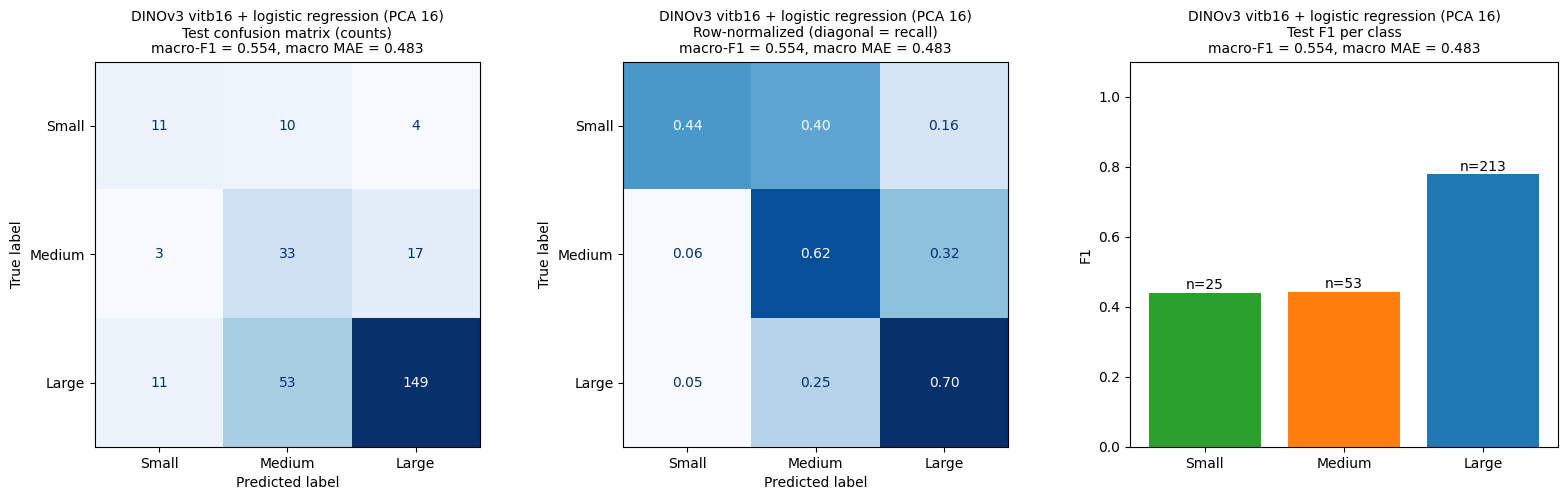

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
model_name = f"DINOv3 {MODEL_NAME.split('_')[1]} + logistic regression ({pca_label(FINAL_DIMS)})"
score_line = f"macro-F1 = {test_scores['macro_f1']:.3f}, macro MAE = {test_scores['macro_mae']:.3f}"
ConfusionMatrixDisplay(confusion_matrix(y["test"], test_pred, labels=[0, 1, 2]), display_labels=CLASS_NAMES).plot(
    ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title(f"{model_name}\nTest confusion matrix (counts)\n{score_line}", fontsize=10)
ConfusionMatrixDisplay(confusion_matrix(y["test"], test_pred, labels=[0, 1, 2], normalize="true"), display_labels=CLASS_NAMES).plot(
    ax=axes[1], cmap="Blues", values_format=".2f", colorbar=False)
axes[1].set_title(f"{model_name}\nRow-normalized (diagonal = recall)\n{score_line}", fontsize=10)
class_counts = np.bincount(y["test"], minlength=3)
bars = axes[2].bar(CLASS_NAMES, per_class_f1, color=CLASS_COLORS)
for k, b in enumerate(bars):
    axes[2].text(b.get_x() + b.get_width() / 2, b.get_height() + 0.01, f"n={class_counts[k]}", ha="center")
axes[2].set_ylim(0, 1.1); axes[2].set_ylabel("F1"); axes[2].set_title(f"{model_name}\nTest F1 per class\n{score_line}", fontsize=10)
plt.tight_layout(); plt.show()

### 11. Compare: baseline, simple, resnet, dino2
bootstrap to get ci, then paired bootstrap.

In [21]:
def bootstrap_ci(pred):
    rng = np.random.default_rng(SEED)
    f1s, maes = [], []
    for _ in range(N_BOOTSTRAP):
        r = rng.integers(0, n_test, n_test)
        f1s.append(macro_f1_fast(y["test"][r], pred[r])); maes.append(macro_mae(y["test"][r], pred[r]))
    return np.percentile(f1s, [2.5, 97.5]), np.percentile(maes, [2.5, 97.5])

def refit(Xm, n_pca, C, weight):
    m = Pipeline([("scale", StandardScaler()),
                  ("pca", PCA(n_components=n_pca, random_state=SEED)),
                  ("logreg", LogisticRegression(C=C, class_weight=weight, max_iter=MAX_ITER, random_state=SEED))])
    m.fit(Xm["train"], y["train"])
    return m, m.predict(Xm["test"])

preds = {"DINOv3": test_pred}
resnet_model = dinov2_model = None
if X_res is not None:
    resnet_model, preds["ResNet-50"] = refit(X_res, RESNET_PCA, RESNET_C, RESNET_WEIGHT)
if X_d2 is not None:
    dinov2_model, preds["DINOv2"] = refit(X_d2, DINOV2_PCA, DINOV2_C, DINOV2_WEIGHT)

f = RESULTS_DIR / "3-simple_model_test_predictions.csv"
if f.exists():
    s = pd.read_csv(f)
    m = splits["test"]["path"].map(dict(zip(s["path"], s["pred"])))
    lab = splits["test"]["path"].map(dict(zip(s["path"], s["label"])))
    if not m.isna().any() and (lab.to_numpy() == y["test"]).all():
        preds["simple features"] = m.to_numpy().astype(int)
    else:
        print("3-simple_model predictions don't match this test set - re-run 3-simple_model")
else:
    print("3-simple_model_test_predictions.csv not found - simple-feature comparison skipped")

rows = [{"model": "majority_class", "test_macro_f1": majority_test_f1, "95% range": "-",
         "test_macro_mae": majority_test_mae, "test_accuracy": baseline_value("majority_class", "test", "accuracy")},
        {"model": "random_guess (mean)", "test_macro_f1": chance_test_f1,
         "95% range": f"{chance_test_range[0]:.3f} - {chance_test_range[1]:.3f} (random runs)",
         "test_macro_mae": chance_test_mae, "test_accuracy": baseline_value("random_guess (mean)", "test", "accuracy")}]
for name in ["simple features", "ResNet-50", "DINOv2", "DINOv3"]:
    if name in preds:
        (lo, hi), _ = bootstrap_ci(preds[name])
        rows.append({"model": name, "test_macro_f1": macro_f1_fast(y["test"], preds[name]),
                     "95% range": f"{lo:.3f} - {hi:.3f} (bootstrap)", "test_macro_mae": macro_mae(y["test"], preds[name]),
                     "test_accuracy": accuracy_score(y["test"], preds[name])})
share_as_good = (guess_f1["test"] >= test_scores["macro_f1"]).mean()
print(f"DINOv3 test macro-F1 {test_scores['macro_f1']:.3f}: {share_as_good:.1%} of random-guessing runs score at least this high.")
comparison = pd.DataFrame(rows).round(3)
comparison

DINOv3 test macro-F1 0.554: 0.0% of random-guessing runs score at least this high.


,model,test_macro_f1,95% range,test_macro_mae,test_accuracy
0,majority_class,0.282,-,1.000,0.732
1,random_guess (mean),0.332,0.279 - 0.389 (random runs),0.940,0.574
2,simple features,0.331,0.290 - 0.370 (bootstrap),0.903,0.567
3,ResNet-50,0.511,0.432 - 0.580 (bootstrap),0.653,0.625
4,DINOv2,0.579,0.496 - 0.648 (bootstrap),0.486,0.680
5,DINOv3,0.554,0.476 - 0.626 (bootstrap),0.483,0.663


In [22]:
def paired(a, b):
    rng = np.random.default_rng(SEED)
    g_f1, g_mae = [], []
    for _ in range(N_BOOTSTRAP):
        r = rng.integers(0, n_test, n_test)
        g_f1.append(macro_f1_fast(y["test"][r], preds[a][r]) - macro_f1_fast(y["test"][r], preds[b][r]))
        g_mae.append(macro_mae(y["test"][r], preds[b][r]) - macro_mae(y["test"][r], preds[a][r]))   # positive = a has fewer steps off
    g_f1, g_mae = np.array(g_f1), np.array(g_mae)
    print(f"{a} vs {b}: macro-F1 gain {macro_f1_fast(y['test'], preds[a]) - macro_f1_fast(y['test'], preds[b]):+.3f} "
          f"(paired 95% {np.percentile(g_f1, 2.5):+.3f} to {np.percentile(g_f1, 97.5):+.3f}, not better in {(g_f1 <= 0).mean():.1%}); "
          f"steps saved {macro_mae(y['test'], preds[b]) - macro_mae(y['test'], preds[a]):+.3f} "
          f"({np.percentile(g_mae, 2.5):+.3f} to {np.percentile(g_mae, 97.5):+.3f})")

for other in ["DINOv2", "ResNet-50", "simple features"]:
    if other in preds:
        paired("DINOv3", other)

if "DINOv2" in preds:
    a_ok, b_ok = test_pred == y["test"], preds["DINOv2"] == y["test"]
    display(pd.DataFrame({"both right": [(a_ok & b_ok).sum()], "only DINOv3 right": [(a_ok & ~b_ok).sum()],
                          "only DINOv2 right": [(~a_ok & b_ok).sum()], "both wrong": [(~a_ok & ~b_ok).sum()]},
                         index=["test maps"]))

DINOv3 vs DINOv2: macro-F1 gain -0.025 (paired 95% -0.075 to +0.025, not better in 84.3%); steps saved +0.002 (-0.065 to +0.078)
DINOv3 vs ResNet-50: macro-F1 gain +0.043 (paired 95% -0.031 to +0.119, not better in 14.9%); steps saved +0.170 (+0.046 to +0.306)
DINOv3 vs simple features: macro-F1 gain +0.223 (paired 95% +0.139 to +0.298, not better in 0.0%); steps saved +0.420 (+0.272 to +0.549)


,both right,only DINOv3 right,only DINOv2 right,both wrong
test maps,180,13,18,80


In [23]:
per_class = pd.DataFrame({"DINOv3 F1": per_class_f1}, index=CLASS_NAMES)
for name in ["DINOv2", "ResNet-50", "simple features"]:
    if name in preds:
        per_class[f"{name} F1"] = f1_score(y["test"], preds[name], labels=[0, 1, 2], average=None, zero_division=0)
per_class["random guessing F1"] = guess_per_class["test"]
per_class["test maps"] = np.bincount(y["test"], minlength=3)
per_class["DINOv3 steps off"] = steps_off_per_class(y["test"], test_pred)
for name in ["DINOv2", "ResNet-50"]:
    if name in preds:
        per_class[f"{name} steps off"] = steps_off_per_class(y["test"], preds[name])
per_class["random steps off"] = guess_steps["test"]
per_class.round(3)

,DINOv3 F1,DINOv2 F1,ResNet-50 F1,simple features F1,random guessing F1,test maps,DINOv3 steps off,DINOv2 steps off,ResNet-50 steps off,random steps off
Small,0.440,0.480,0.419,0.000,0.083,25,0.720,0.760,1.120,1.647
Medium,0.443,0.472,0.375,0.270,0.183,53,0.377,0.358,0.491,0.815
Large,0.778,0.784,0.739,0.722,0.730,213,0.352,0.338,0.347,0.359


### 12. Check incorrect predictions

Large called Medium: 53 test maps
Medium called Large: 17 test maps
Small called Large: 4 test maps
Small called Medium: 10 test maps


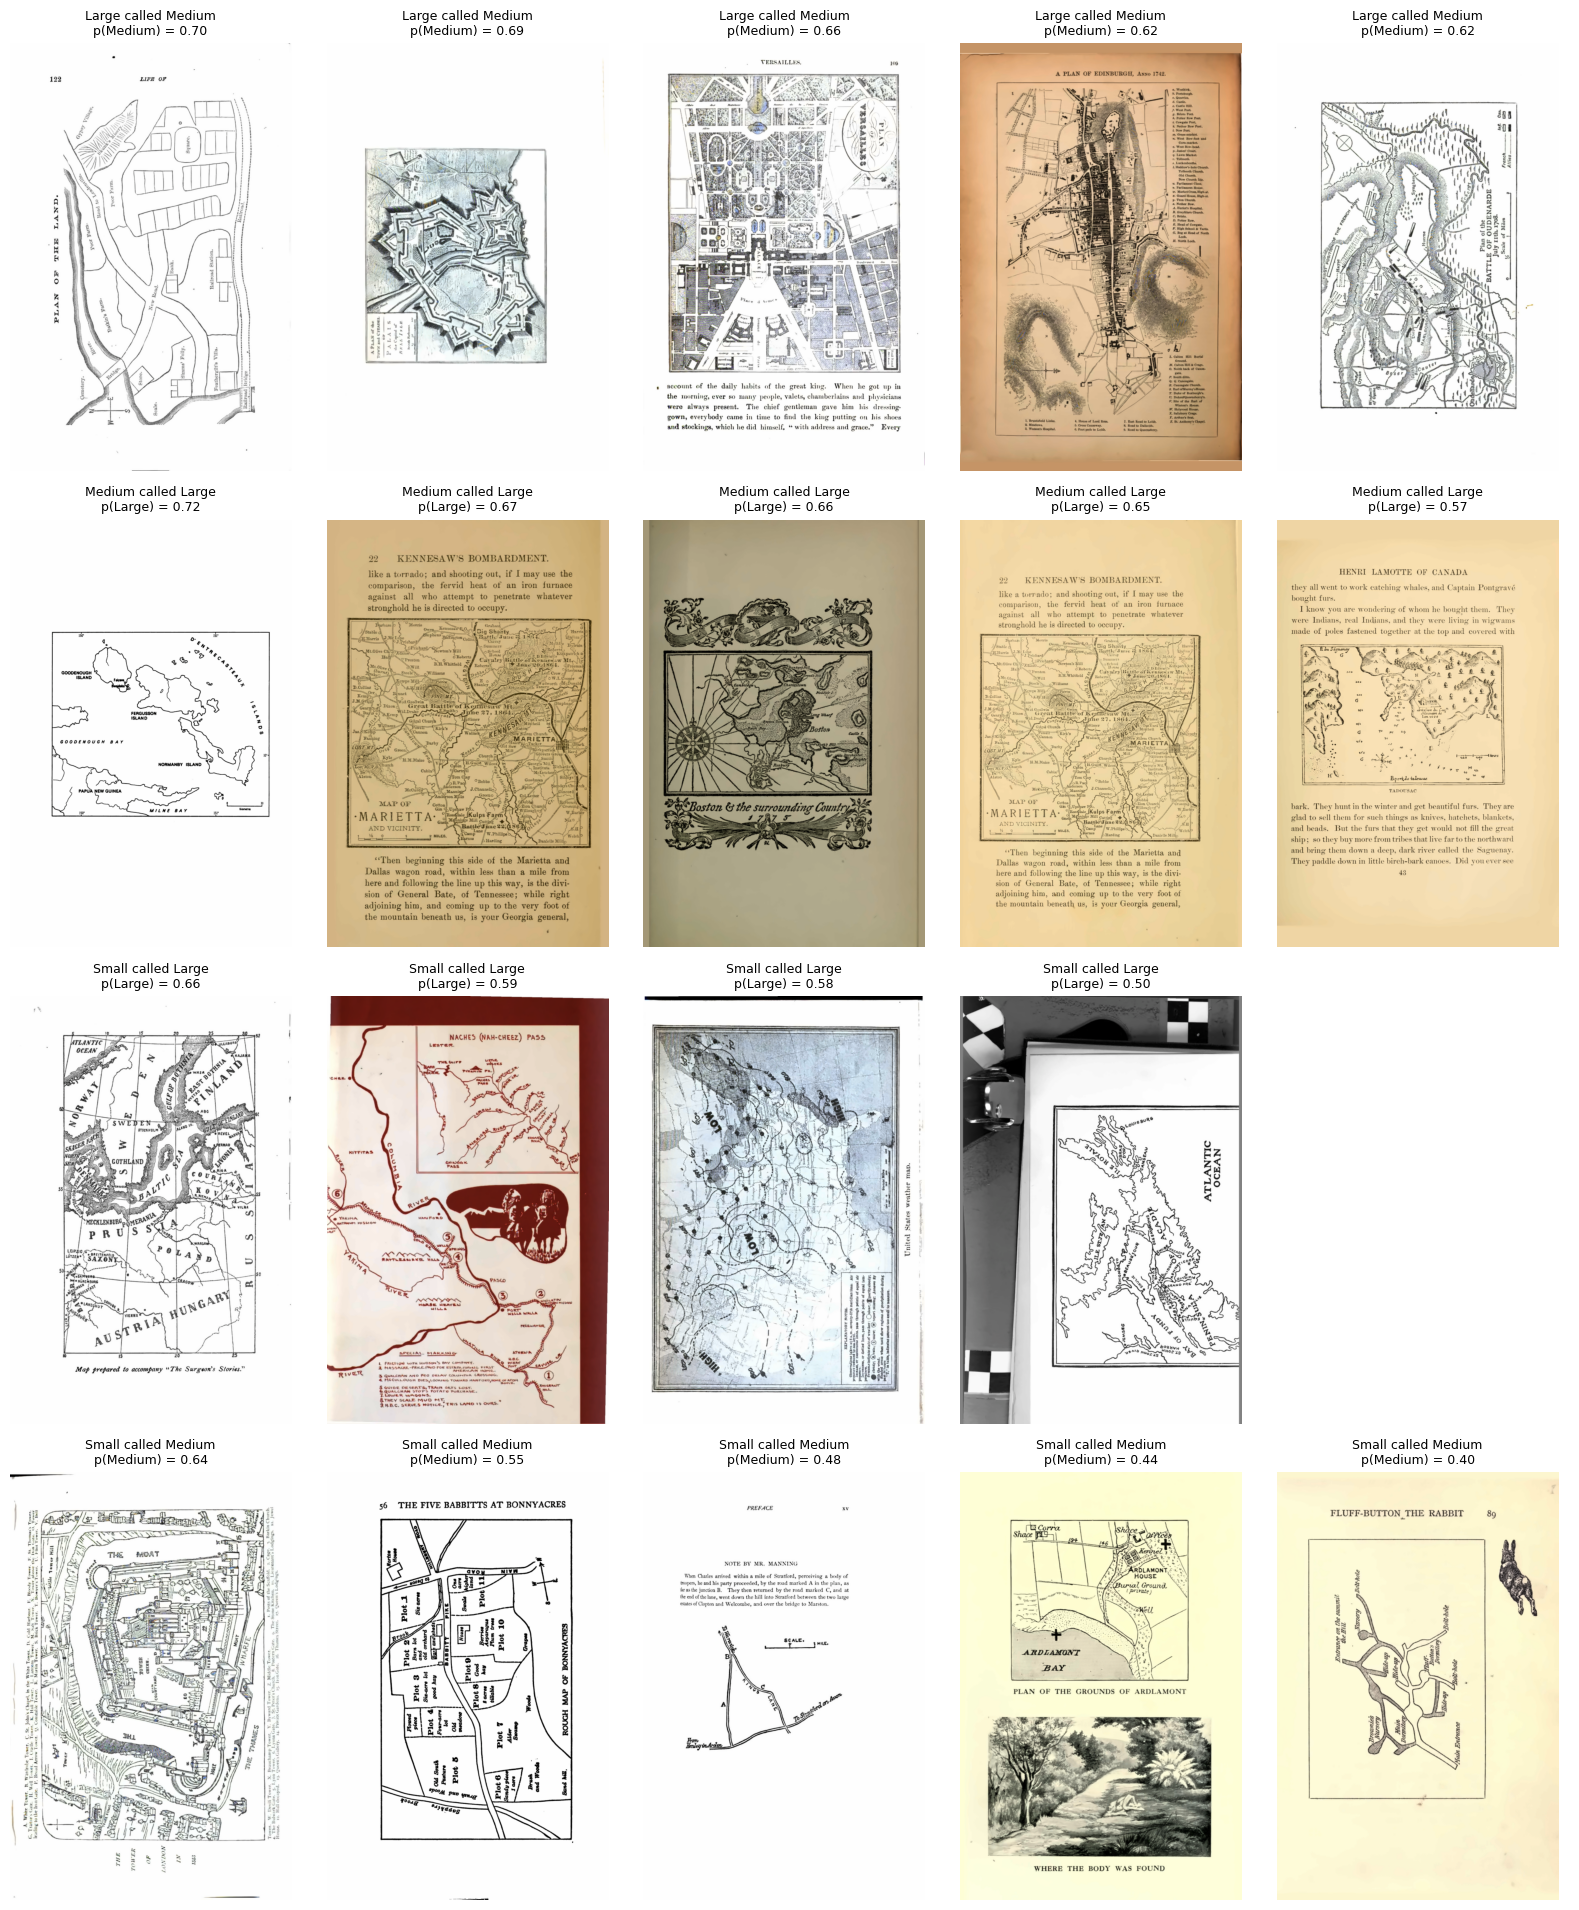

By label_conflict:


,test maps,share correct
label_conflict,,
False,280,0.675
True,11,0.364


By fictionality:


,test maps,share correct
fictionality,,
fictional,101,0.485
real,190,0.758


In [24]:
test_proba = final_model.predict_proba(X["test"])
mistakes = [(2, 1), (1, 2), (0, 2), (0, 1)]   # (true, predicted)
fig, axes = plt.subplots(len(mistakes), N_GALLERY, figsize=(3.2 * N_GALLERY, 4.8 * len(mistakes)))
for row, (tc, pc) in enumerate(mistakes):
    found = np.where((y["test"] == tc) & (test_pred == pc))[0]
    found = found[np.argsort(-test_proba[found, pc])][:N_GALLERY]
    print(f"{CLASS_NAMES[tc]} called {CLASS_NAMES[pc]}: {((y['test'] == tc) & (test_pred == pc)).sum()} test maps")
    for col in range(N_GALLERY):
        ax = axes[row, col]; ax.axis("off")
        if col < len(found):
            i = found[col]
            with Image.open(PROC / splits["test"]["path"][i]) as img:
                ax.imshow(img.convert("RGB"))
            ax.set_title(f"{CLASS_NAMES[tc]} called {CLASS_NAMES[pc]}\np({CLASS_NAMES[pc]}) = {test_proba[i, pc]:.2f}", fontsize=9)
plt.tight_layout(); plt.show()

test_rows = splits["test"].assign(correct=(test_pred == y["test"]))
for column in ["label_conflict", "fictionality"]:
    if column in test_rows.columns:
        print(f"By {column}:")
        display(test_rows.groupby(column)["correct"].agg(["count", "mean"])
                .rename(columns={"count": "test maps", "mean": "share correct"}).round(3))

### 13. Correct for class mix.
Similar to Bayes-offset in the resnet notebook

In [25]:
real_mix = np.bincount(y_train_maps, minlength=3) / len(y_train_maps)
train_mix = np.full(3, 1 / 3) if FINAL_WEIGHTING == "balanced" else np.bincount(y["train"], minlength=3) / len(y["train"])
prior_offset = np.log(real_mix / train_mix); prior_offset -= prior_offset[2]

log_proba = {s: np.log(np.clip(final_model.predict_proba(X[s]), 1e-12, None)) for s in ["val", "test"]}
def predict_with(offset, split):
    return np.argmax(log_proba[split] + np.asarray(offset), axis=1)
assert np.array_equal(predict_with(np.zeros(3), "test"), test_pred)

grid_f1 = np.array([[macro_f1_fast(y["val"], predict_with([s, m, 0.0], "val")) for m in OFFSET_GRID] for s in OFFSET_GRID])
bi, bj = np.unravel_index(np.argmax(grid_f1), grid_f1.shape)
best_val_pred = predict_with([OFFSET_GRID[bi], OFFSET_GRID[bj], 0.0], "val")
best_se = np.std([macro_f1_fast(y["val"][r], best_val_pred[r]) for r in val_resamples])
sg, mg = np.meshgrid(OFFSET_GRID, OFFSET_GRID, indexing="ij")
tied_grid = grid_f1 >= grid_f1[bi, bj] - best_se
pi, pj = np.unravel_index(np.argmin(np.where(tied_grid, np.hypot(sg, mg), np.inf)), grid_f1.shape)
tuned_offset = np.array([OFFSET_GRID[pi], OFFSET_GRID[pj], 0.0])
print(f"Prior-correction offsets (S, M): {prior_offset[0]:+.2f}, {prior_offset[1]:+.2f}")
print(f"Best on val: {OFFSET_GRID[bi]:+.2f}, {OFFSET_GRID[bj]:+.2f} (val macro-F1 {grid_f1[bi, bj]:.3f}, SE {best_se:.3f})")
print(f"Tuned (one-SE): {tuned_offset[0]:+.2f}, {tuned_offset[1]:+.2f} (val macro-F1 {grid_f1[pi, pj]:.3f})")

versions = {"original": np.zeros(3), "prior correction": prior_offset, "tuned offsets (one-SE)": tuned_offset}
rng = np.random.default_rng(SEED)
draws = [rng.integers(0, n_test, n_test) for _ in range(N_BOOTSTRAP)]
vrows = []
for name, off in versions.items():
    vp_val, vp_test = predict_with(off, "val"), predict_with(off, "test")
    gain = [macro_f1_fast(y["test"][r], vp_test[r]) - macro_f1_fast(y["test"][r], test_pred[r]) for r in draws]
    vrows.append({"version": name, "Small off": off[0], "Medium off": off[1],
                  "val macro-F1": macro_f1_fast(y["val"], vp_val), "test macro-F1": macro_f1_fast(y["test"], vp_test),
                  "test macro MAE": macro_mae(y["test"], vp_test), "test accuracy": accuracy_score(y["test"], vp_test),
                  "test predicted (S,M,L)": str(tuple(int(n) for n in np.bincount(vp_test, minlength=3))),
                  "gain vs original (paired 95%)": "-" if name == "original" else
                      f"{np.mean(gain):+.3f} ({np.percentile(gain, 2.5):+.3f} to {np.percentile(gain, 97.5):+.3f})"})
display(pd.DataFrame(vrows).set_index("version").round(3))

Prior-correction offsets (S, M): -1.39, -1.38
Best on val: -0.10, -0.20 (val macro-F1 0.623, SE 0.037)
Tuned (one-SE): +0.00, +0.00 (val macro-F1 0.602)


,Small off,Medium off,val macro-F1,test macro-F1,test macro MAE,test accuracy,"test predicted (S,M,L)",gain vs original (paired 95%)
version,,,,,,,,
original,0.000,0.000,0.602,0.554,0.483,0.663,"(25, 96, 170)",-
prior correction,-1.386,-1.378,0.354,0.314,0.966,0.722,"(5, 4, 282)",-0.238 (-0.321 to -0.151)
tuned offsets (one-SE),0.000,0.000,0.602,0.554,0.483,0.663,"(25, 96, 170)",+0.000 (+0.000 to +0.000)


### 14. Efficiency

In [26]:
print(pd.DataFrame([
    {"model": "DINOv2 (5-dinov2)", "inference ms/image (CPU, 1 thread)": DINOV2_MS_PER_IMAGE},
    {"model": f"DINOv3 + {pca_label(FINAL_DIMS)} + LR", "inference ms/image (CPU, 1 thread)":
        embed_ms_per_image + 1000 * predict_seconds / n_test},
]).round(1).to_string(index=False))
print(f"\nDINOv3 fit (scale + PCA + LR): {fit_seconds:.2f} s; embedding all "
      f"{sum(len(splits[s]) for s in splits)} images on {extract_device['train']}: {sum(extract_seconds.values()):.0f} s")

               model  inference ms/image (CPU, 1 thread)
   DINOv2 (5-dinov2)                               203.3
DINOv3 + PCA 16 + LR                               156.0

DINOv3 fit (scale + PCA + LR): 0.13 s; embedding all 3654 images on mps: 280 s


### Save results and pca

In [27]:
(ci_f1, ci_mae) = bootstrap_ci(test_pred)
results = {
    "run_date": time.strftime("%Y-%m-%d"), "model": HF_NAME, "pooling": POOLING, "embed_size": list(EMBED_SIZE),
    "pca_dims": FINAL_DIMS, "class_weight": FINAL_WEIGHTING, "C": FINAL_C, "selection_rule": SELECTION_RULE,
    "split_fingerprint": SPLIT_FINGERPRINT,
    "val_macro_f1": float(val_scores["macro_f1"]), "test_macro_f1": float(test_scores["macro_f1"]),
    "test_macro_f1_95ci": [float(v) for v in ci_f1], "test_macro_mae": float(test_scores["macro_mae"]),
    "test_macro_mae_95ci": [float(v) for v in ci_mae], "test_accuracy": float(test_scores["accuracy"]),
    "inference_ms_per_image": float(embed_ms_per_image + 1000 * predict_seconds / n_test),
}
(RESULTS_DIR / "6-dinov3.json").write_text(json.dumps(results, indent=2))
pd.DataFrame({"path": splits["test"]["path"], "label": y["test"], "pred": test_pred}).to_csv(
    RESULTS_DIR / "6-dinov3_test_predictions.csv", index=False)

def save_pca_features(tag, pipeline, Xm):
    transform = pipeline[:-1]            # scaler + PCA, without the logistic regression
    for s in splits:
        Z = transform.transform(Xm[s]).astype(np.float32)
        np.savez(FEATURE_DIR / f"{tag}_{s}.npz", X=Z, paths=np.array(splits[s]["path"]), y=y[s])
    print(f"saved {tag}_<split>.npz  ({Z.shape[1]} columns)")

save_pca_features(f"dinov3_pca{FINAL_DIMS}" if FINAL_DIMS < EMBED_DIM else "dinov3_scaled", final_model, X)
if resnet_model is not None: save_pca_features(f"resnet50_pca{RESNET_PCA}", resnet_model, X_res)
if dinov2_model is not None: save_pca_features(f"dinov2_pca{DINOV2_PCA}", dinov2_model, X_d2)
print("Saved results to", RESULTS_DIR)

saved dinov3_pca16_<split>.npz  (16 columns)
saved resnet50_pca64_<split>.npz  (64 columns)
saved dinov2_pca32_<split>.npz  (32 columns)
Saved results to /Users/hsinyehtsai/281/281project/data/results
